# Circuit de Décision — XGBoost + TreeSHAP
**KIAMA · Strategic Compass AI**

Ce notebook couvre l'intégralité du circuit de décision GO/NO-GO pour les appels d'offres :
1. Chargement des données (profil entreprise + DAOs)
2. Feature engineering (`core_logic.py`)
3. Entraînement XGBoost
4. Prédiction sur un AO concret
5. Explainability — TreeSHAP (waterfall, beeswarm, feature importance)
6. Comparaison règle métier vs modèle XGBoost

---
> **Pré-requis** : installer les dépendances puis lancer depuis `decision_engine/`
> ```bash
> cd decision_engine
> pip install -r requirements.txt
> jupyter notebook notebooks/decision_circuit.ipynb
> ```

In [1]:
# ── Imports ───────────────────────────────────────────────────────────────────
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import joblib
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings('ignore')

# ── Résolution robuste du dossier decision_engine/ ────────────────────────────
# Remonte depuis le CWD courant jusqu'à trouver un dossier contenant src/.
# Fonctionne que Jupyter soit lancé depuis decision_engine/ ou notebooks/.
ROOT = Path('.').resolve()
for _ in range(4):
    if (ROOT / 'src').exists():
        break
    ROOT = ROOT.parent
else:
    raise RuntimeError(
        "Impossible de localiser decision_engine/src/. "
        "Lancez Jupyter depuis decision_engine/ : "
        "cd decision_engine && jupyter notebook"
    )

if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from core_logic import DAOProcessor, FEATURE_COLUMNS

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
print(f'✓ Imports OK  |  ROOT = {ROOT}')

✓ Imports OK  |  ROOT = C:\KIAMA\Divers\decision_engine


## 1. Chargement des données

In [2]:
# ── Profil entreprise ─────────────────────────────────────────────────────────
PROFILE_PATH = ROOT / 'data' / 'company_profile.json'
with open(PROFILE_PATH, encoding='utf-8') as f:
    company = json.load(f)

print(f"Entreprise  : {company['company_name']}")
print(f"CA annuel   : {company['annual_revenue']:,} FCFA")
print(f"Trésorerie  : {company['available_cash']:,} FCFA")
print(f"Ligne crédit: {company['credit_line']:,} FCFA")
print(f"Domaines    : {', '.join(company['domaines'][:4])} …")

Entreprise  : KIAMA
CA annuel   : 100,000,000 FCFA
Trésorerie  : 15,000,000 FCFA
Ligne crédit: 25,000,000 FCFA
Domaines    : Systèmes d'information, Développement logiciel, Intelligence artificielle, Transformation numérique …


In [3]:
# ── DAOs d'entraînement ───────────────────────────────────────────────────────
# Priorité : data/training/ (JSON individuels), sinon data/raw/resultats.json
TRAINING_DIR = ROOT / 'data' / 'training'
RAW_PATH     = ROOT / 'data' / 'raw' / 'resultats.json'

daos = []
if TRAINING_DIR.is_dir():
    for fp in sorted(TRAINING_DIR.glob('*.json')):
        data = json.loads(fp.read_text(encoding='utf-8'))
        daos.extend(data if isinstance(data, list) else [data])
elif RAW_PATH.is_file():
    data = json.loads(RAW_PATH.read_text(encoding='utf-8'))
    daos = data if isinstance(data, list) else [data]
else:
    raise FileNotFoundError(
        f"Aucune donnée trouvée dans {TRAINING_DIR} ni {RAW_PATH}"
    )

print(f'{len(daos)} DAO(s) chargé(s)')

70 DAO(s) chargé(s)


## 2. Feature Engineering

In [4]:
# ── Calcul des features ───────────────────────────────────────────────────────
processor = DAOProcessor()
daos = processor.dedupe_daos(daos)

rows = [processor.calculate_features(d, company) for d in daos]
df = pd.DataFrame(rows)

print(f"Dataset : {len(df)} lignes × {len(df.columns)} colonnes")
print(f"GO      : {(df['label_decision'] == 1).sum()}")
print(f"NO-GO   : {(df['label_decision'] == 0).sum()}")
df[FEATURE_COLUMNS + ['label_decision']].describe().round(3)

Dataset : 55 lignes × 8 colonnes
GO      : 29
NO-GO   : 26


,ratio_ca,ratio_credit,poids_caution,score_tech,label_decision
count,55.000,55.000,55.000,55.000,55.000
mean,3.841,2.400,0.254,0.310,0.527
std,3.413,2.133,0.230,0.248,0.504
min,0.400,0.250,0.017,0.000,0.000
25%,1.245,0.775,0.063,0.170,0.000
50%,2.500,1.560,0.160,0.330,1.000
75%,5.000,3.120,0.400,0.500,1.000
max,13.330,8.330,0.800,0.670,1.000


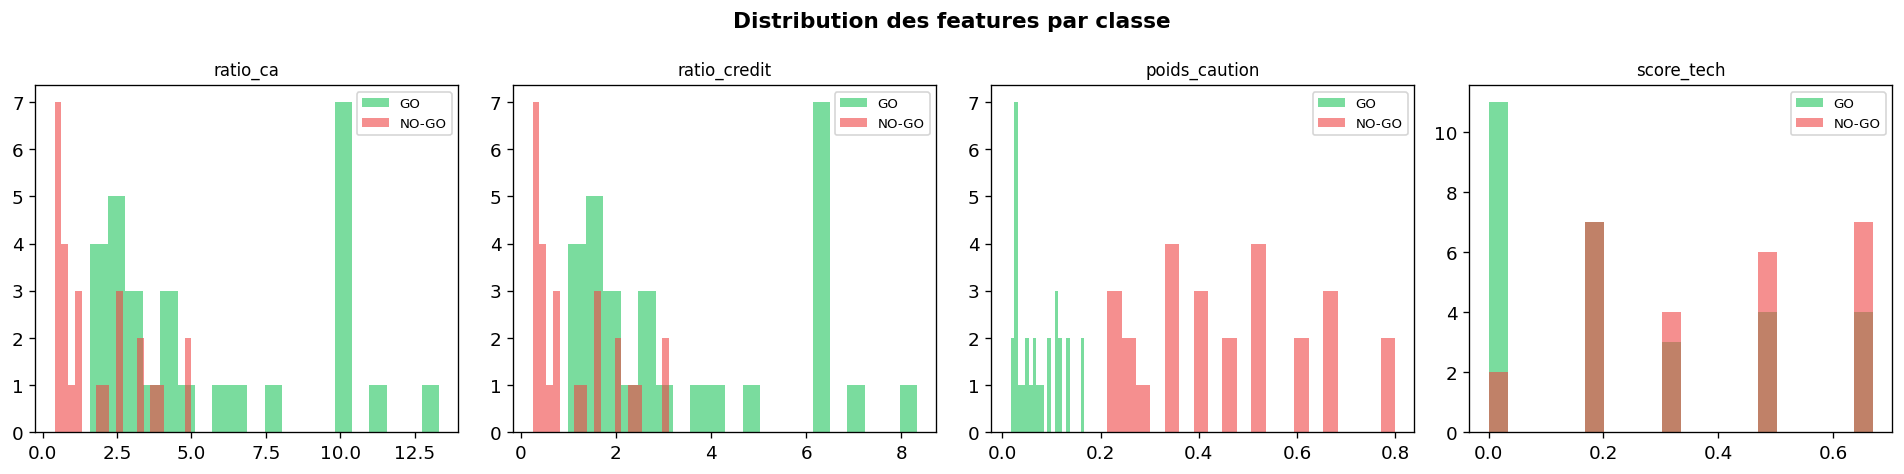

In [5]:
# ── Distribution des features par classe ─────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
colors = {'GO': '#22c55e', 'NO-GO': '#ef4444'}

for ax, col in zip(axes, FEATURE_COLUMNS):
    for label_val, label_name in [(1, 'GO'), (0, 'NO-GO')]:
        subset = df[df['label_decision'] == label_val][col]
        ax.hist(subset, bins=20, alpha=0.6, color=colors[label_name], label=label_name)
    ax.set_title(col, fontsize=10)
    ax.legend(fontsize=8)

fig.suptitle('Distribution des features par classe', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Entraînement XGBoost

In [6]:
# ── Split train / test ────────────────────────────────────────────────────────
X = df[FEATURE_COLUMNS]
y = df['label_decision']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y if y.nunique() > 1 else None,
)
print(f"Train : {len(X_train)} | Test : {len(X_test)}")

Train : 44 | Test : 11


In [7]:
# ── Entraînement ──────────────────────────────────────────────────────────────
model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
)
model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False,
)

acc = model.score(X_test, y_test)
print(f"Précision test : {acc:.2%}")
print()
print(classification_report(
    y_test, model.predict(X_test),
    target_names=['NO-GO', 'GO'],
    zero_division=0,
))

Précision test : 90.91%

              precision    recall  f1-score   support

       NO-GO       1.00      0.80      0.89         5
          GO       0.86      1.00      0.92         6

    accuracy                           0.91        11
   macro avg       0.93      0.90      0.91        11
weighted avg       0.92      0.91      0.91        11



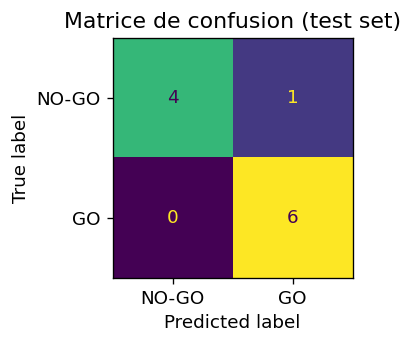

In [8]:
# ── Matrice de confusion ──────────────────────────────────────────────────────
if len(X_test) > 0:
    fig, ax = plt.subplots(figsize=(4, 3))
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=['NO-GO', 'GO']).plot(ax=ax, colorbar=False)
    ax.set_title('Matrice de confusion (test set)')
    plt.tight_layout()
    plt.show()
else:
    print('Dataset trop petit pour un jeu de test.')

In [9]:
# ── Sauvegarde du modèle ──────────────────────────────────────────────────────
MODEL_PATH = ROOT / 'models' / 'decision_model.pkl'
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(model, MODEL_PATH)
print(f'✓ Modèle sauvegardé → {MODEL_PATH}')

✓ Modèle sauvegardé → C:\KIAMA\Divers\decision_engine\models\decision_model.pkl


## 4. Prédiction sur un appel d'offres concret

In [10]:
# ── AO exemple ────────────────────────────────────────────────────────────────
# Par défaut : dernier DAO du dataset.
# Pour cibler un fichier spécifique, décommentez la ligne suivante :
# dao_exemple = json.loads(Path('data/raw/mon_ao.json').read_text(encoding='utf-8'))
dao_exemple = daos[-1]

features   = processor.calculate_features(dao_exemple, company)
X_exemple  = processor.features_to_frame(features)

pred           = int(model.predict(X_exemple)[0])
proba          = model.predict_proba(X_exemple)[0]
confidence_go  = float(proba[1] * 100)

print(f"Référence      : {features['ref_dao']}")
print(f"Budget         : {features['budget_fcfa']:,} FCFA")
print(f"Caution        : {features['caution_fcfa']:,} FCFA")
print()
print("Features :")
for col in FEATURE_COLUMNS:
    print(f"  {col:20s} = {features[col]}")
print()
print(f"Verdict XGBoost : {'GO ✅' if pred == 1 else 'NO-GO ❌'}")
print(f"Confiance GO    : {confidence_go:.1f} %")
print(f"Règle métier    : {'GO' if processor.compute_label(features) == 1 else 'NO-GO'}")

Référence      : SYN-NOGO-010
Budget         : 55,000,000 FCFA
Caution        : 4,000,000 FCFA

Features :
  ratio_ca             = 3.64
  ratio_credit         = 2.27
  poids_caution        = 0.2667
  score_tech           = 0.5

Verdict XGBoost : NO-GO ❌
Confiance GO    : 6.0 %
Règle métier    : NO-GO


## 5. Explainability — TreeSHAP

In [11]:
# ── Initialisation TreeSHAP ───────────────────────────────────────────────────
# TreeExplainer utilise l'algorithme exact de Shapley pour les modèles d'arbres.
# Plus rapide et plus précis que KernelExplainer.
explainer   = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)   # array (n_samples × n_features)

print(f"Shape SHAP values   : {np.array(shap_values).shape}")
print(f"Expected value base : {explainer.expected_value:.4f}")
print()
print("Les valeurs SHAP représentent la contribution de chaque feature")
print("à la déviation par rapport à la prédiction moyenne (log-odds GO).")

Shape SHAP values   : (55, 4)
Expected value base : 0.2409

Les valeurs SHAP représentent la contribution de chaque feature
à la déviation par rapport à la prédiction moyenne (log-odds GO).


In [12]:
# ── Tableau des contributions SHAP pour l'AO exemple ─────────────────────────
shap_vals_ex = explainer.shap_values(X_exemple)
vals = np.array(shap_vals_ex)[0]   # XGBoost binaire : array 1D (n_features,)

contrib_df = pd.DataFrame({
    'Feature'          : FEATURE_COLUMNS,
    'Valeur'           : [features[c] for c in FEATURE_COLUMNS],
    'SHAP (impact GO)' : [round(float(v), 4) for v in vals],
    'Direction'        : ['▲ GO' if v >= 0 else '▼ NO-GO' for v in vals],
}).sort_values('SHAP (impact GO)', key=abs, ascending=False)

print(f"Expected value  : {explainer.expected_value:.4f}")
print(f"Somme SHAP      : {float(sum(vals)):.4f}")
print(f"Score brut      : {explainer.expected_value + float(sum(vals)):.4f}  →  {confidence_go:.1f} % GO")
print()
contrib_df

Expected value  : 0.2409
Somme SHAP      : -2.9905
Score brut      : -2.7496  →  6.0 % GO



,Feature,Valeur,SHAP (impact GO),Direction
2,poids_caution,0.2667,-2.8359,▼ NO-GO
3,score_tech,0.5000,-0.0954,▼ NO-GO
0,ratio_ca,3.6400,-0.0592,▼ NO-GO
1,ratio_credit,2.2700,0.0000,▲ GO


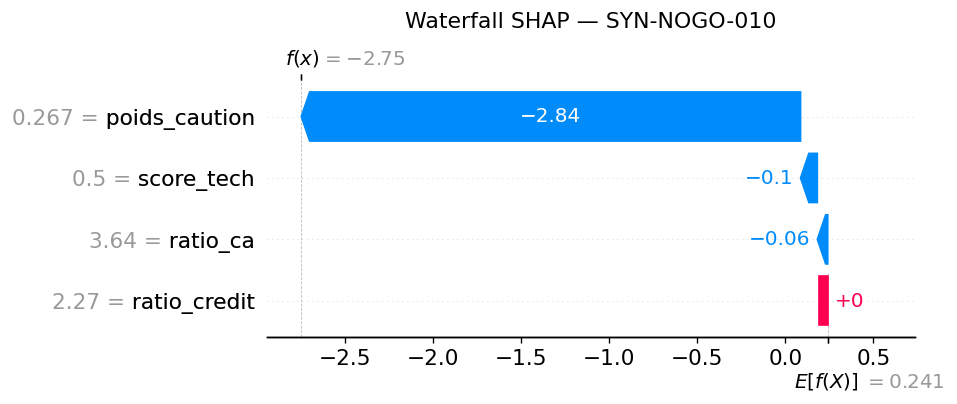

In [13]:
# ── Waterfall plot — explication individuelle ─────────────────────────────────
shap_obj = explainer(X_exemple)
shap.plots.waterfall(shap_obj[0], max_display=10, show=False)
plt.title(f"Waterfall SHAP — {str(features['ref_dao'])[:50]}", pad=12)
plt.tight_layout()
plt.show()

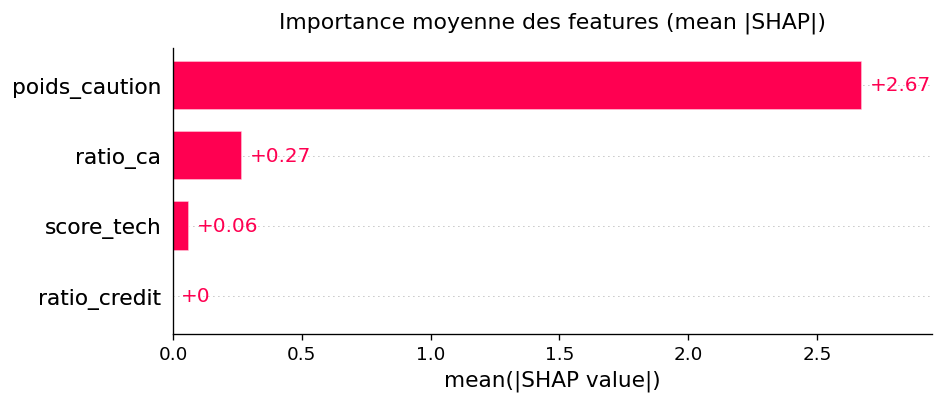

In [14]:
# ── Bar plot — importance moyenne |SHAP| sur tout le dataset ─────────────────
shap_all = explainer(X)
shap.plots.bar(shap_all, max_display=10, show=False)
plt.title('Importance moyenne des features (mean |SHAP|)', pad=12)
plt.tight_layout()
plt.show()

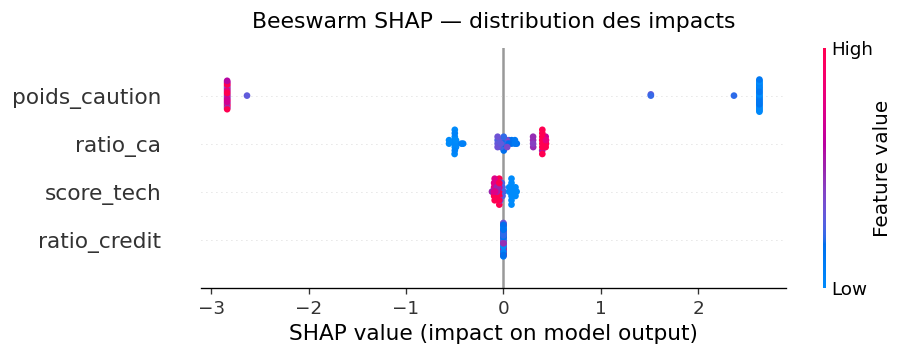

In [15]:
# ── Beeswarm — distribution des impacts sur l'ensemble des AOs ───────────────
shap.plots.beeswarm(shap_all, max_display=10, show=False)
plt.title('Beeswarm SHAP — distribution des impacts', pad=12)
plt.tight_layout()
plt.show()

## 6. Comparaison règle métier vs XGBoost

In [16]:
# ── Accord / désaccord ────────────────────────────────────────────────────────
df['xgb_pred']     = model.predict(X)
df['xgb_proba_go'] = model.predict_proba(X)[:, 1]

accord      = (df['label_decision'] == df['xgb_pred']).mean()
desaccords  = df[df['label_decision'] != df['xgb_pred']]

print(f"Accord règle ↔ XGBoost : {accord:.2%}")
print(f"Cas ambigus             : {len(desaccords)} / {len(df)}")

if len(desaccords) > 0:
    print()
    print("Détail des cas où XGBoost diverge de la règle :")
    cols_show = FEATURE_COLUMNS + ['label_decision', 'xgb_pred', 'xgb_proba_go']
    print(desaccords[cols_show].to_string())

Accord règle ↔ XGBoost : 98.18%
Cas ambigus             : 1 / 55

Détail des cas où XGBoost diverge de la règle :
    ratio_ca  ratio_credit  poids_caution  score_tech  label_decision  xgb_pred  xgb_proba_go
28      1.25          0.78         0.2133        0.67               0         1      0.785355


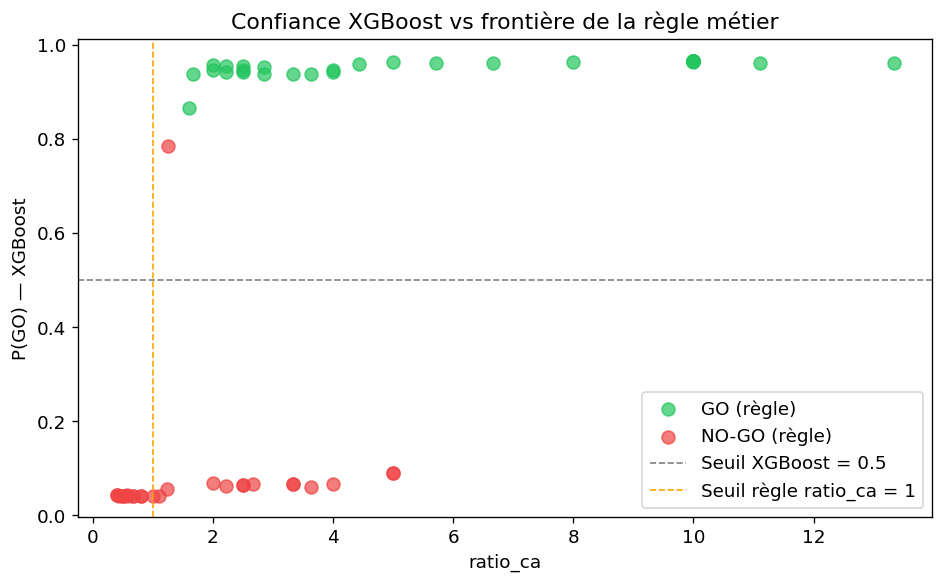

In [17]:
# ── Scatter : P(GO) XGBoost vs ratio_ca (frontière de la règle) ──────────────
fig, ax = plt.subplots(figsize=(8, 5))

for label_val, label_name, color in [(1, 'GO (règle)', '#22c55e'), (0, 'NO-GO (règle)', '#ef4444')]:
    mask = df['label_decision'] == label_val
    ax.scatter(
        df.loc[mask, 'ratio_ca'],
        df.loc[mask, 'xgb_proba_go'],
        c=color, alpha=0.7, label=label_name, s=60,
    )

ax.axhline(0.5, color='gray',   linestyle='--', linewidth=1, label='Seuil XGBoost = 0.5')
ax.axvline(1.0, color='orange', linestyle='--', linewidth=1, label='Seuil règle ratio_ca = 1')
ax.set_xlabel('ratio_ca')
ax.set_ylabel('P(GO) — XGBoost')
ax.set_title('Confiance XGBoost vs frontière de la règle métier')
ax.legend()
plt.tight_layout()
plt.show()

In [18]:
# ── Synthèse ──────────────────────────────────────────────────────────────────
print('=' * 55)
print('SYNTHÈSE — Circuit de Décision KIAMA')
print('=' * 55)
print(f'Modèle       : XGBoost ({model.n_estimators} arbres, max_depth={model.max_depth})')
print(f'Features     : {FEATURE_COLUMNS}')
print(f'Dataset      : {len(df)} DAOs')
print(f'Précision    : {acc:.2%}  (test set 20 %)')
print(f'Accord règle : {accord:.2%}')
print(f'Cas ambigus  : {len(desaccords)}  (frontière souple vs règle dure)')
print()
print('TreeSHAP actif — chaque prédiction retourne les contributions')
print('par feature (ratio_ca, ratio_credit, poids_caution, score_tech).')
print('=' * 55)

SYNTHÈSE — Circuit de Décision KIAMA
Modèle       : XGBoost (200 arbres, max_depth=4)
Features     : ['ratio_ca', 'ratio_credit', 'poids_caution', 'score_tech']
Dataset      : 55 DAOs
Précision    : 90.91%  (test set 20 %)
Accord règle : 98.18%
Cas ambigus  : 1  (frontière souple vs règle dure)

TreeSHAP actif — chaque prédiction retourne les contributions
par feature (ratio_ca, ratio_credit, poids_caution, score_tech).
